## Load python modules

In [1]:
import numpy as np
import pyvista as pv
from cmcrameri import cm
import matplotlib.pyplot as plt
import math
from numpy import log as ln
import scipy.special as sp

plt.rcParams["figure.dpi"] = 100
plt.rc("savefig", dpi=600)
palette_colors = ["#3288bd", "#d53e4f", "#99d594", "#fc8d59"]
pi = math.pi
hyp2f1 = sp.hyp2f1
plt.rcParams["font.size"] = 14
plt.rcParams["font.sans-serif"] = ["Computer Modern Sans Serif"]
plt.rcParams["text.usetex"] = True

# Analytical solutions

In [2]:
# Material and model parameters (Gc0, he and ls are set with the mesh data above)
E = 17e9  # Young’s modulus E (Pa)
nu = 0.2  # Poisson’s ratio
mu = 0.01  # dynamic viscosity (Pa.s)
Q = 2e-3  # flow rate (m^2/s)
he = 0.5  # element size along the fracture path (m)
ls = 1.0  # phase-field length scale (m)
Gc0 = 60.0  # Griffith energy (Pa.m)
Gc = Gc0 * (3.0 * he / 8.0 / ls + 1.0)
K_IC = (E * Gc / (1 - nu**2)) ** 0.5
E_prime = E / (1 - nu**2)
mu_prime = 12 * mu
K_prime = 4 * (2 / pi) ** 0.5 * K_IC
# If it is viscous-dominated domain: K < K_0 =0.7,
K_viscosity = K_prime / E_prime * (E_prime / mu_prime / Q) ** 0.25
print(K_viscosity)

0.5933285612843724


# Viscous-dominated solutions:

$w(x,t)=\frac{{\mu^\prime}^{1/6}Q_0^{1/2}t^{1/3}}{{E^\prime}^{1/6}}[\gamma_0+\mathcal{E}(\mathcal{K})\gamma_1][\bar{\Omega}_0(\xi)+\mathcal{E}(\mathcal{K})\bar{\Omega}_1(\xi)]$

$p(x,t)=p_f-\sigma_0=\frac{{\mu^\prime}^{1/3}{E^\prime}^{2/3}}{t^{1/3}}[\Pi_0(\xi)+\mathcal{E}(\mathcal{K})\Pi_1(\xi)]$

$l(t)=\frac{Q_0^{1/2}{E^\prime}^{1/6}t^{2/3}}{{\mu^\prime}^{1/6}}[\gamma_0+\mathcal{E}(\mathcal{K})\gamma_1]$


## For $\mathcal{E}(\mathcal{K})$:


In [4]:
E_K = 0.1076 * K_viscosity**3.16796

## For $\bar{\Omega}_0$:


In [5]:
a01 = 1.73205
a02 = -0.15601
a03 = 0.13264
b01 = 0.475449
b02 = -0.061178
b03 = 0.066322


def Omega_0(xi_i):
    Omega_0 = (
        a01 * (1 - xi_i**2) ** (2 / 3)
        + a02 * (1 - xi_i**2) ** (5 / 3)
        + a03
        * (
            2 * (1 - xi_i**2) ** 0.5
            + xi_i**2 * ln(abs((1 - (1 - xi_i**2) ** 0.5) / (1 + (1 - xi_i**2) ** 0.5)))
        )
    )
    return Omega_0

## For ${\Pi}_0$:


In [7]:
b01 = 0.475449
b02 = -0.061178
b03 = 0.066322
# b02 = -0.15601 * 10 / 7  # From Santill 2017, which is not accurate


def Pi_0(xi_i):
    Pi_0 = (
        b01 * hyp2f1(-1 / 6, 1, 1 / 2, xi_i**2)
        + b02 * hyp2f1(-7 / 6, 1, 1 / 2, xi_i**2)
        + b03 * (2 - pi * abs(xi_i))
    )
    return Pi_0

## For $\bar{\Omega}_1$:


In [8]:
h = 0.13867
a11 = 0.908354
a12 = 0.025574
a13 = -0.083814
a14 = -0.09095


def Omega_1(xi_i):
    Omega_1 = (
        a11 * (1 - xi_i**2) ** h
        + (a12 + a13 * xi_i**2) * (1 - xi_i**2) ** (1 + h)
        + a14
        * (
            2 * (1 - xi_i**2) ** 0.5
            + xi_i**2 * ln(abs((1 - (1 - xi_i**2) ** 0.5) / (1 + (1 - xi_i**2) ** 0.5)))
        )
    )
    return Omega_1

## For ${\Pi}_1$:


In [9]:
b11 = 0.170654
b12 = 0.017132
b13 = -0.039015
b14 = -0.045476
c11 = 0.36133
c12 = -1.63867
c13 = -0.638673


def Pi_1(xi_i):
    Pi_1 = (
        b11 * hyp2f1(c11, 1, 1 / 2, xi_i**2)
        + b12 * hyp2f1(c12, 1, 1 / 2, xi_i**2)
        + b13 * xi_i**2 * hyp2f1(c13, 2, 3 / 2, xi_i**2)
        + b14 * (2 - pi * abs(xi_i))
    )
    return Pi_1

# For $l(t)$:

$l(t)=\frac{Q_0^{1/2}{E^\prime}^{1/6}t^{2/3}}{{\mu^\prime}^{1/6}}[\gamma_0+\mathcal{E}(\mathcal{K})\gamma_1]=L(t)[\gamma_0+\mathcal{E}(\mathcal{K})\gamma_1]$

$L(t)=\frac{Q_0^{1/2}{E^\prime}^{1/6}t^{2/3}}{{\mu^\prime}^{1/6}}$


In [10]:
gamma_0 = 0.6152
gamma_1 = -0.01887


def l_t(t_i):
    Lt = Q**0.5 * E_prime ** (1 / 6) * t_i ** (2 / 3) / (mu_prime ** (1 / 6))
    l_t = Lt * (gamma_0 + E_K * gamma_1)
    return l_t

# For $w(x,t)$:

$w(x,t)=\frac{{\mu^\prime}^{1/6}Q_0^{1/2}t^{1/3}}{{E^\prime}^{1/6}}[\gamma_0+\mathcal{E}(\mathcal{K})\gamma_1][\bar{\Omega}_0(\xi)+\mathcal{E}(\mathcal{K})\bar{\Omega}_1(\xi)] =\varepsilon(t)*l(t)*\bar{\Omega}(\xi,\mathcal{K})$

$\varepsilon(t) = \frac{Q_0t}{L^2}$


In [11]:
def w_x_t(xi_i, t_i):
    Lt = Q**0.5 * E_prime ** (1 / 6) * t_i ** (2 / 3) / (mu_prime ** (1 / 6))
    eps = Q * t_i / Lt**2
    w = eps * Lt * (Omega_0(xi_i) + E_K * Omega_1(xi_i)) * (gamma_0 + E_K * gamma_1)
    return w

# For $p(x,t)$:

$p(x,t)=p_f-\sigma_0=\frac{{\mu^\prime}^{1/3}{E^\prime}^{2/3}}{t^{1/3}}[\Pi_0(\xi)+\mathcal{E}(\mathcal{K})\Pi_1(\xi)]=\varepsilon(t)E^\prime \Pi(\xi,\mathcal{K})$


In [12]:
def p_x_t(xi_i, t_i):
    Lt = Q**0.5 * E_prime ** (1 / 6) * t_i ** (2 / 3) / (mu_prime ** (1 / 6))
    eps = Q * t_i / Lt**2
    p = eps * E_prime * (Pi_0(xi_i) + E_K * Pi_1(xi_i))
    return p

In [ ]:
xi = np.linspace(0.01, 1, 100)
t = np.linspace(0.0, 200, 200)
opening = np.zeros((len(xi), len(t)))
pressure = np.zeros((len(xi), len(t)))
length = []

openingCenter = []
pressureCenter = []
tCenter = []
for j in range(len(t)):
    if j > 0:
        t_i = t[j]
        length.append(l_t(t_i))
        for i in range(len(xi)):
            xi_i = xi[i]

            if xi_i == 0.01:
                tCenter.append(t_i)
                openingCenter.append(w_x_t(xi_i, t_i))
                pressureCenter.append(p_x_t(xi_i, t_i))

            opening[i][j] = w_x_t(xi_i, t_i)
            pressure[i][j] = p_x_t(xi_i, t_i)

## Plot analytical solutions

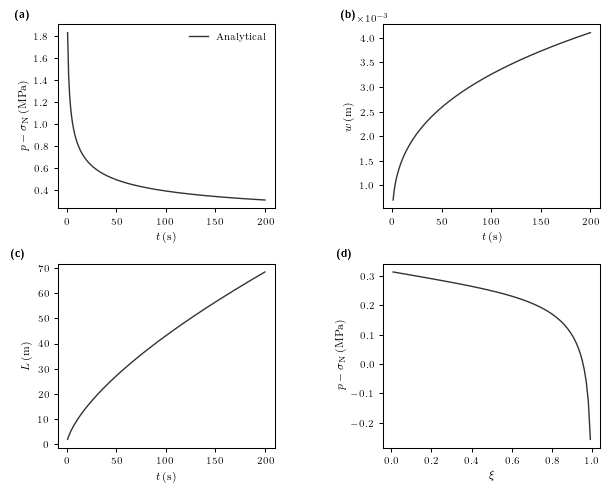

In [ ]:
t_target = 200.0
t_idx_ana = np.argmin(np.abs(t[1:] - t_target)) + 1
# 2x2 figure (Science double-column: 7 in wide)
fig, axes = plt.subplots(
    2, 2, figsize=(7, 5.5), gridspec_kw={"hspace": 0.3, "wspace": 0.5}
)

for ax in axes.flat:
    for spine in ax.spines.values():
        spine.set_linewidth(0.75)
    ax.tick_params(direction="out", length=3, width=0.75, labelsize=7)

# Panel (a): pressure vs time
ax0 = axes[0, 0]
ax0.plot(
    tCenter,
    np.array(pressureCenter) / 1e6,
    color="#333333",
    linestyle="-",
    linewidth=1.0,
    label=r"$\mathrm{Analytical}$",
)
ax0.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax0.set_ylabel(r"$p-\sigma_{\mathrm{N}}\,\mathrm{(MPa)}$", fontsize=8)
ax0.legend(fontsize=7, frameon=False)
ax0.text(-0.2, 1.02, r"\textbf{(a)}", transform=ax0.transAxes, fontsize=8, va="bottom")

# Panel (b): fracture opening vs time
ax1 = axes[0, 1]
ax1.plot(tCenter, openingCenter, color="#333333", linestyle="-", linewidth=1.0)
ax1.ticklabel_format(style="sci", scilimits=(-1, 2), axis="y")
ot = ax1.yaxis.get_offset_text()
ot.set_fontsize(7)
ot.set_x(-0.12)
ax1.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax1.set_ylabel(r"$w\,\mathrm{(m)}$", fontsize=8)
ax1.text(-0.2, 1.02, r"\textbf{(b)}", transform=ax1.transAxes, fontsize=8, va="bottom")

# Panel (c): crack length vs time
ax2 = axes[1, 0]
ax2.plot(tCenter, length, color="#333333", linestyle="-", linewidth=1.0)
ax2.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax2.set_ylabel(r"$L\,\mathrm{(m)}$", fontsize=8)
ax2.text(-0.22, 1.02, r"\textbf{(c)}", transform=ax2.transAxes, fontsize=8, va="bottom")

# Panel (d): net pressure profile along fracture at t = 200 s
ax3 = axes[1, 1]
ax3.plot(
    xi, pressure[:, t_idx_ana] / 1e6, color="#333333", linestyle="-", linewidth=1.0
)
ax3.set_xlabel(r"$\xi$", fontsize=8)
ax3.set_ylabel(r"$p-\sigma_\mathrm{N}\,\mathrm{(MPa)}$", fontsize=8)
ax3.text(-0.22, 1.02, r"\textbf{(d)}", transform=ax3.transAxes, fontsize=8, va="bottom")

# plt.savefig("KGD_viscous_analytical.pdf", bbox_inches="tight", dpi=300)
plt.show()

## Compare numerical results with analytical solutions

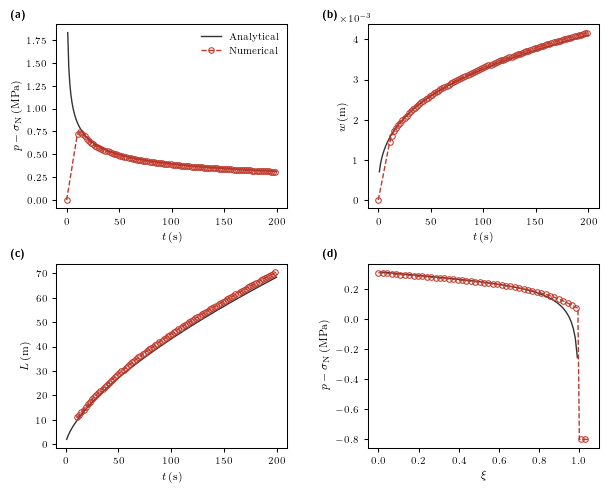

In [21]:
# Build the 2x2 figure from the exported CSVs from the numerical simulation.
# This cell needs nothing from the cells above: it reads the four files and plots
# them, so the same figure can be produced anywhere the CSVs are available.
import matplotlib.pyplot as plt
import numpy as np

_rd = lambda f: np.genfromtxt(f, delimiter=",", names=True)
num_ts = _rd("../../data/M_vertex/numerical_timeseries.csv")
num_pr = _rd("../../data/M_vertex/numerical_profile_t200.csv")

# the masks the figure above applies (t <= 200 s, xi <= 1.05)
m_t = (num_ts["time_s"] >= 0) & (num_ts["time_s"] <= 200)
m_x = (num_pr["xi"] >= 0) & (num_pr["xi"] <= 1.05)

# panel tags fall back to plain text where LaTeX is not configured
_tag = (
    (lambda s: rf"\textbf{{({s})}}")
    if plt.rcParams["text.usetex"]
    else (lambda s: f"({s})")
)
ANA = dict(color="#333333", linestyle="-", linewidth=1.0)
NUM = dict(
    linestyle="--",
    color="#c0392b",
    linewidth=1.0,
    marker="o",
    markersize=4,
    markerfacecolor="none",
    markeredgewidth=0.75,
    markevery=2,
)

fig, axes = plt.subplots(
    2, 2, figsize=(7, 5.5), gridspec_kw={"hspace": 0.3, "wspace": 0.35}
)
for ax in axes.flat:
    for spine in ax.spines.values():
        spine.set_linewidth(0.75)
    ax.tick_params(direction="out", length=3, width=0.75, labelsize=7)

# (a) pressure vs time
ax0 = axes[0, 0]
ax0.plot(
    tCenter,
    np.array(pressureCenter) / 1e6,
    label=r"$\mathrm{Analytical}$",
    **ANA,
)
ax0.plot(
    num_ts["time_s"][m_t],
    num_ts["net_pressure_Pa"][m_t] / 1e6,
    label=r"$\mathrm{Numerical}$",
    **NUM,
)
ax0.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax0.set_ylabel(r"$p-\sigma_{\mathrm{N}}\,\mathrm{(MPa)}$", fontsize=8)
ax0.legend(fontsize=7, frameon=False, loc="upper right")
ax0.text(-0.2, 1.02, _tag("a"), transform=ax0.transAxes, fontsize=8, va="bottom")

# (b) opening vs time
ax1 = axes[0, 1]
ax1.plot(tCenter, openingCenter, **ANA)
ax1.plot(num_ts["time_s"][m_t], num_ts["opening_m"][m_t], **NUM)
ax1.ticklabel_format(style="sci", scilimits=(-1, 2), axis="y")
ot = ax1.yaxis.get_offset_text()
ot.set_fontsize(7)
ot.set_x(-0.12)
ax1.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax1.set_ylabel(r"$w\,\mathrm{(m)}$", fontsize=8)
ax1.text(-0.2, 1.02, _tag("b"), transform=ax1.transAxes, fontsize=8, va="bottom")

# (c) crack length vs time
ax2 = axes[1, 0]
ax2.plot(tCenter, length, **ANA)
ax2.plot(num_ts["time_s"][m_t], num_ts["half_length_surface_m"][m_t], **NUM)
ax2.set_xlabel(r"$t\,\mathrm{(s)}$", fontsize=8)
ax2.set_ylabel(r"$L\,\mathrm{(m)}$", fontsize=8)
ax2.text(-0.2, 1.02, _tag("c"), transform=ax2.transAxes, fontsize=8, va="bottom")

# (d) pressure profile at t = 100 s
ax3 = axes[1, 1]
ax3.plot(xi, pressure[:, t_idx_ana] / 1e6, **ANA)
ax3.plot(
    num_pr["xi"][m_x],
    num_pr["net_pressure_Pa"][m_x] / 1e6,
    **{**NUM, "markevery": 3},
)
ax3.set_xlabel(r"$\xi$", fontsize=8)
ax3.set_ylabel(r"$p-\sigma_\mathrm{N}\,\mathrm{(MPa)}$", fontsize=8)
ax3.text(-0.2, 1.02, _tag("d"), transform=ax3.transAxes, fontsize=8, va="bottom")

plt.savefig("../../figures/KGD_viscous_results.pdf", bbox_inches="tight", dpi=300)
plt.show()